In [11]:
#
#
#
import arslabrobotics as ar

import numpy as np
import scipy

data = np.loadtxt("ball_data.txt")
(rows, _) = data.shape

arx = ar.identification.ARXSolver(data, 4, 0)
(a, b) = arx.solve()

print("a,b:", a,b)
print()

# y(k) + a1 * y(k-1) + a2 * y(k-2) + .... = b1 * u(k) + b2 * u(k-1) * b3 * u(k-2) ... 

# Discrete system mnodel
# x1 = -a1 * x1 - a2 * x2 - a3 * x3 - a4 * x4 + b * u
# x2 = x1
# x3 = x2
# x4 = x3
# x5 = x1 + x5 (x1 is the speed, so x5 is the position)

A = np.array([ [ -a[0],  -a[1], -a[2], -a[3],  0], 
               [     1,      0,     0,     0,  0], 
               [     0,      1,     0,     0,  0], 
               [     0,      0,     1,     0,  0], 
               [     1,      0,     0,     0,  1], 
             ])
B = np.array([ b, [0], [0], [0] ,[0]])

print("State Matrix:\n", A)
print("Input Matrix:\n", B)


a,b: [0.6096579399500802, -0.27235914492321317, -0.7169959223997919, -0.6124142582988547] [0.001570242108334008]

State Matrix:
 [[-0.60965794  0.27235914  0.71699592  0.61241426  0.        ]
 [ 1.          0.          0.          0.          0.        ]
 [ 0.          1.          0.          0.          0.        ]
 [ 0.          0.          1.          0.          0.        ]
 [ 1.          0.          0.          0.          1.        ]]
Input Matrix:
 [[0.00157024]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]]


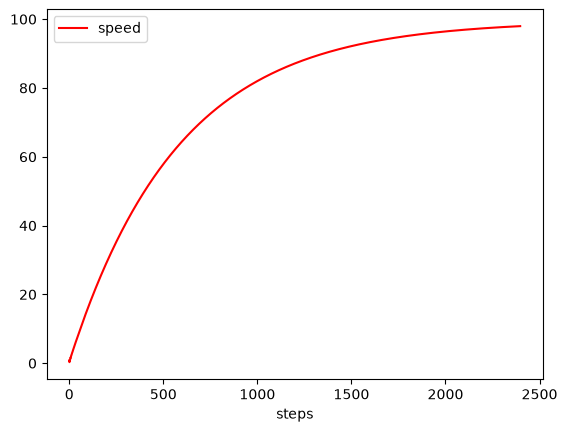

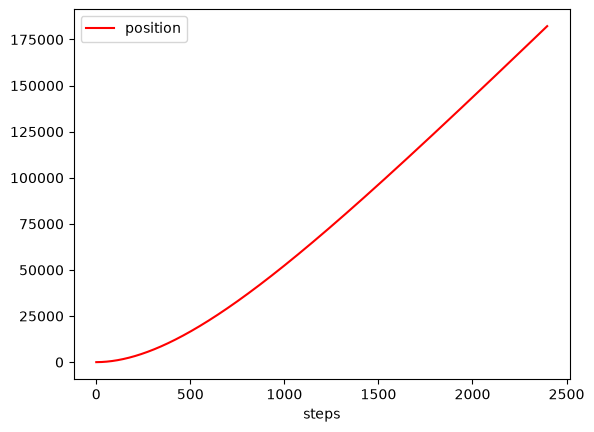

In [12]:
# testing the system
x = np.array([ 0., 0., 0., 0., 0.])

dps = DataPlotter()
dps.set_x("steps")
dps.add_y("speed", "speed")

dpp = DataPlotter()
dpp.set_x("steps")
dpp.add_y("pos", "position")

for t in range(rows):
    u = np.array([500]) # 500 N of input
    x = A @ x + B @ u
    dps.append_x(t)
    dps.append_y("speed", x[0])
    dpp.append_x(t)
    dpp.append_y("pos", x[4])

dps.plot()
dpp.plot()


In [14]:
# computing optimal gain

Q = np.eye( 5, dtype=np.float32)
R = np.eye( 1, dtype=np.float32)

P = scipy.linalg.solve_discrete_are(A, B, Q, R)
K = np.linalg.inv(R + B.T @ P @ B) @ B.T @ P @ A

print("Optimal Gain:", K)


Optimal Gain: [[15.6593245  24.42253791 20.46438044  9.48749903  0.98776205]]


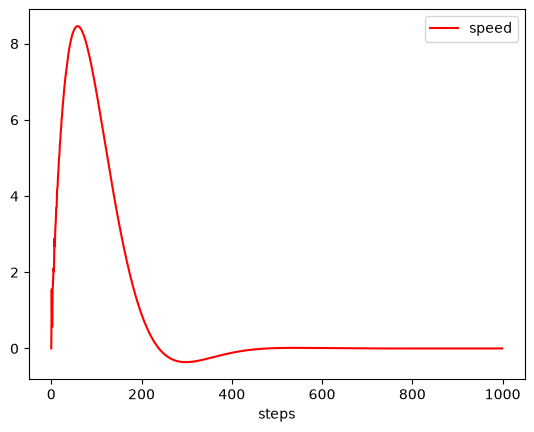

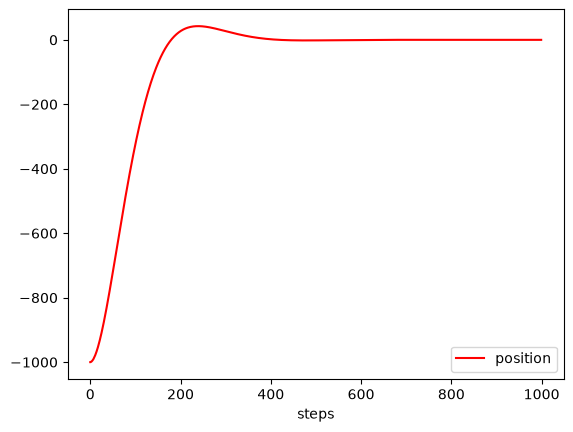

In [16]:

# starting position = -1000
# starting speed = 0
x = np.array([ 0., 0.0, 0.0, 0.0, -1000.])

dps = DataPlotter()
dps.set_x("steps")
dps.add_y("speed", "speed")

dpp = DataPlotter()
dpp.set_x("steps")
dpp.add_y("pos", "position")

for t in range(1000):
    dps.append_x(t)
    dps.append_y("speed", x[0])
    dpp.append_x(t)
    dpp.append_y("pos", x[4])
    u = - K @ x
    x = A @ x + B @ u

dps.plot()
dpp.plot()
